> 🔓 **SOLUTIONS EDITION**: this is the instructor copy with worked solutions and executed outputs. Please attempt every problem in the student notebook first; struggling is where learning happens.

# 📘 Lesson 1: Simple Linear Regression
*One feature, one line: the foundation of almost everything that follows*

| ⏱️ Time | 🎚️ Level | 🧰 Prerequisites |
|---|---|---|
| ~100 min | 🟢 Beginner | Lesson 00; high-school algebra; mean & variance |

---
## 🎬 The Hook
You run a small company and you've spent different amounts on TV ads in 200 different markets. Sales went up where you spent more. Your boss asks the million-shilling question:

> *"If we spend 150 thousand on TV next quarter, how many units will we sell?"*

You could eyeball it. You could draw a line with a ruler. But **which** line? Two people with two rulers draw two lines. Today we turn "draw a good line" into mathematics, so that everyone gets the *same, provably best* line.

---
## 🎯 Learning Objectives
By the end of this notebook you will be able to:

1. Describe regression as 'fitting the best straight line' and say what *best* means.
2. Derive and compute the slope and intercept using the least-squares formulas.
3. Implement simple linear regression **from scratch** (closed form *and* gradient descent).
4. Use scikit-learn's `LinearRegression`, and interpret `coef_` and `intercept_` in real units.
5. Check the model's assumptions with residual plots.
6. Recognise the dangers: outliers, extrapolation, and Anscombe's quartet.
7. Quantify uncertainty with the bootstrap.

## 🗺️ Roadmap

- The idea: a line through a cloud
- The math of 'best': least squares
- A hand-worked example
- Building it from scratch (closed form)
- Building it again with gradient descent
- scikit-learn version
- Residuals & assumptions
- Danger zone: outliers, Anscombe, extrapolation
- Uncertainty with the bootstrap
- Cheat-sheet: parameters, pros/cons, complexity, use cases
- Worked examples, problems, quiz

> 💡 **How to use this notebook:** run cells top to bottom. Read the text *before* you run the code. When you reach a 🧩 **Problem**, try it yourself first, open the hints one at a time, and only then peek at the solutions notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))      # so we can import course_utils.py
from course_utils import *                      # np, pd, plt, check(), data_path(), ...
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
RANDOM_STATE = 42
print("Setup complete ✅")
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

Setup complete ✅


---
## 🧠 1. The idea: a line through a cloud

Simple linear regression models the target as a straight-line function of **one** feature:

$$\hat{y} = \beta_0 + \beta_1 x$$

- $\beta_0$ is the **intercept**: the predicted y when x = 0.
- $\beta_1$ is the **slope**: how much the prediction changes when x increases by 1 unit.
- $\hat{y}$ ("y-hat") is the *prediction*; the real value is $y$. The gap $e_i = y_i - \hat y_i$ is the **residual**.

Let's look at the cloud we want to fit a line through:

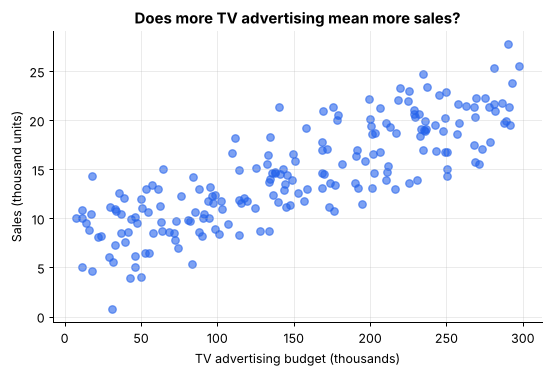

Correlation between TV budget and sales: r = 0.828


In [2]:
ads = pd.read_csv(data_path("advertising.csv"))
x = ads["tv_budget_k"].values
y = ads["sales_k_units"].values

plt.scatter(x, y, alpha=0.6)
plt.xlabel("TV advertising budget (thousands)"); plt.ylabel("Sales (thousand units)")
plt.title("Does more TV advertising mean more sales?")
plt.show()
print(f"Correlation between TV budget and sales: r = {np.corrcoef(x, y)[0, 1]:.3f}")

There is a clear upward trend with scatter around it. Our task: find the line $\beta_0 + \beta_1 x$ that sits *closest* to all points. "Closest" needs a precise definition. Here's the famous one.

---
## 📐 2. The math of 'best': ordinary least squares (OLS)

For any candidate line, each point has a residual $e_i = y_i - (\beta_0 + \beta_1 x_i)$. We score a line by the **Sum of Squared Errors**:

$$\text{SSE}(\beta_0,\beta_1)=\sum_{i=1}^{n}\bigl(y_i-\beta_0-\beta_1x_i\bigr)^2$$

The **best** line is the one with the smallest SSE. *Why squares?* (1) positive and negative errors can't cancel, (2) big mistakes are punished more, (3) the result is a smooth bowl-shaped function with **one** minimum we can solve exactly.

### Solving it with calculus

At the minimum of a bowl, the slope is zero in every direction, so we set both partial derivatives to zero:

$$\frac{\partial\,\text{SSE}}{\partial\beta_0}=-2\sum (y_i-\beta_0-\beta_1x_i)=0
\qquad
\frac{\partial\,\text{SSE}}{\partial\beta_1}=-2\sum x_i(y_i-\beta_0-\beta_1x_i)=0$$

These are two linear equations (the *normal equations*) in two unknowns. Solving them gives the celebrated closed form:

$$\boxed{\;\beta_1=\frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}=\frac{\text{Cov}(x,y)}{\text{Var}(x)}=r\,\frac{s_y}{s_x}\;}
\qquad
\boxed{\;\beta_0=\bar y-\beta_1\bar x\;}$$

**Read it in English:**
- The slope is *how much x and y move together* divided by *how much x moves on its own*.
- The second equation says the best line **always passes through the centre of the cloud** $(\bar x,\bar y)$.
- $r$ is the correlation coefficient. Steeper slope ⇔ stronger correlation *or* y varies a lot relative to x.

> 📐 **Math note.**
>
> For simple regression, $R^2 = r^2$ (the squared correlation). So $r=0.78 \Rightarrow R^2\approx 0.61$: the line explains about 61 % of the variation in y.

---
## ✍️ 3. A hand-worked example (do this once in your life)

Five students: hours studied $x$ and test score $y$ (out of 5, to keep arithmetic friendly).

| i | $x_i$ | $y_i$ | $x_i-\bar x$ | $y_i-\bar y$ | $(x_i-\bar x)(y_i-\bar y)$ | $(x_i-\bar x)^2$ |
|---|---|---|---|---|---|---|
| 1 | 1 | 2 | −2 | −2 | 4 | 4 |
| 2 | 2 | 4 | −1 | 0 | 0 | 1 |
| 3 | 3 | 5 | 0 | 1 | 0 | 0 |
| 4 | 4 | 4 | 1 | 0 | 0 | 1 |
| 5 | 5 | 5 | 2 | 1 | 2 | 4 |
| **Σ** | 15 | 20 | | | **6** | **10** |

With $\bar x=3$ and $\bar y=4$:

- Slope: $\beta_1 = 6/10 = \mathbf{0.6}$
- Intercept: $\beta_0 = 4 - 0.6\times 3 = \mathbf{2.2}$
- Prediction for 6 hours: $2.2+0.6\times6=5.8$ (careful: that's above the maximum score of 5. Extrapolation is dangerous!)
- Fit quality: predictions are 2.8, 3.4, 4.0, 4.6, 5.2 → residuals −0.8, 0.6, 1.0, −0.6, −0.2 → SSE $=2.4$; SST $=\sum (y-\bar y)^2=6$ → $R^2=1-2.4/6=\mathbf{0.6}$.

In [3]:
xh = np.array([1, 2, 3, 4, 5]); yh = np.array([2, 4, 5, 4, 5])
b1 = np.sum((xh - xh.mean()) * (yh - yh.mean())) / np.sum((xh - xh.mean()) ** 2)
b0 = yh.mean() - b1 * xh.mean()
sse = np.sum((yh - (b0 + b1 * xh)) ** 2); sst = np.sum((yh - yh.mean()) ** 2)
print(f"slope={b1:.2f}  intercept={b0:.2f}  SSE={sse:.2f}  R²={1 - sse / sst:.2f}")

slope=0.60  intercept=2.20  SSE=2.40  R²=0.60


---
## 🔧 4. Build it from scratch (closed form)

Now we turn those two formulas into a reusable class with the same shape as scikit-learn's API. Writing this yourself is the best way to demystify "machine learning": it is just arithmetic.

In [4]:
class SimpleLinearRegressionScratch:
    """Least-squares line y = b0 + b1 * x, solved with the closed-form formulas."""

    def fit(self, x, y):
        x = np.asarray(x, dtype=float).ravel()
        y = np.asarray(y, dtype=float).ravel()
        x_bar, y_bar = x.mean(), y.mean()
        self.slope_ = np.sum((x - x_bar) * (y - y_bar)) / np.sum((x - x_bar) ** 2)
        self.intercept_ = y_bar - self.slope_ * x_bar
        return self

    def predict(self, x):
        return self.intercept_ + self.slope_ * np.asarray(x, dtype=float).ravel()

    def score(self, x, y):
        """R² = 1 - SSE/SST"""
        y = np.asarray(y, dtype=float).ravel()
        sse = np.sum((y - self.predict(x)) ** 2)
        sst = np.sum((y - y.mean()) ** 2)
        return 1 - sse / sst


mine = SimpleLinearRegressionScratch().fit(x, y)
print(f"Scratch   : intercept={mine.intercept_:.5f}  slope={mine.slope_:.5f}  R²={mine.score(x, y):.5f}")

sk = LinearRegression().fit(x.reshape(-1, 1), y)
print(f"scikit-learn: intercept={sk.intercept_:.5f}  slope={sk.coef_[0]:.5f}  R²={sk.score(x.reshape(-1, 1), y):.5f}")

slope_np, intercept_np = np.polyfit(x, y, 1)
print(f"np.polyfit: intercept={intercept_np:.5f}  slope={slope_np:.5f}")

Scratch   : intercept=6.76368  slope=0.05119  R²=0.68571
scikit-learn: intercept=6.76368  slope=0.05119  R²=0.68571
np.polyfit: intercept=6.76368  slope=0.05119


Three completely different code paths, identical answers to 5 decimals. Now let's **see** the line and *interpret* it.

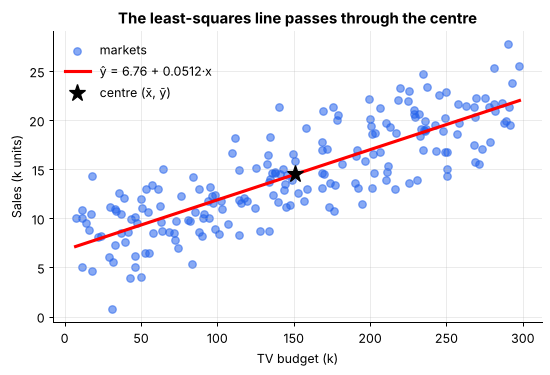

INTERPRETATION: each extra 1k spent on TV is associated with about 51 extra units sold.
With zero TV spend we'd still expect about 6,764 units (other channels, brand, etc.).


In [5]:
plt.scatter(x, y, alpha=0.55, label="markets")
xs = np.linspace(x.min(), x.max(), 100)
plt.plot(xs, mine.predict(xs), "r", lw=2.5, label=f"ŷ = {mine.intercept_:.2f} + {mine.slope_:.4f}·x")
plt.plot(x.mean(), y.mean(), "k*", ms=14, label="centre (x̄, ȳ)")
plt.xlabel("TV budget (k)"); plt.ylabel("Sales (k units)"); plt.legend(); plt.title("The least-squares line passes through the centre"); plt.show()

print(f"INTERPRETATION: each extra 1k spent on TV is associated with about {mine.slope_*1000:.0f} extra units sold.")
print(f"With zero TV spend we'd still expect about {mine.intercept_*1000:,.0f} units (other channels, brand, etc.).")

> ⚠️ **Watch out.**
>
> "Associated with" is not "caused by". Regression finds patterns in the data you have; it does not prove that spending *causes* sales. (Maybe the company advertises more in markets that were already booming.)

---
## 👁️ Seeing the loss: why there is exactly one best line

Let's compute SSE for a grid of (intercept, slope) pairs. The result is a smooth bowl, and our closed-form answer sits at the bottom.

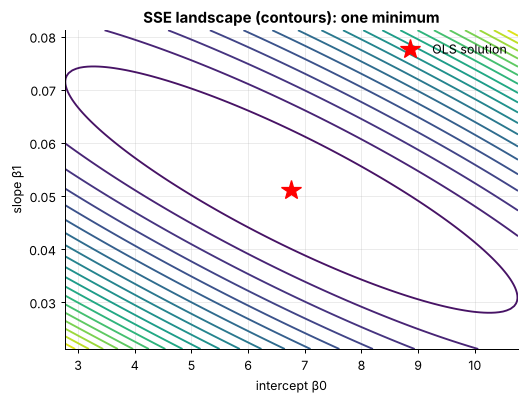

In [6]:
b0_grid = np.linspace(mine.intercept_ - 4, mine.intercept_ + 4, 120)
b1_grid = np.linspace(mine.slope_ - 0.03, mine.slope_ + 0.03, 120)
B0, B1 = np.meshgrid(b0_grid, b1_grid)
SSE = ((y[None, None, :] - (B0[..., None] + B1[..., None] * x[None, None, :])) ** 2).sum(axis=2)

plt.figure(figsize=(6.5, 4.6))
cs = plt.contour(B0, B1, SSE, levels=25, cmap="viridis")
plt.plot(mine.intercept_, mine.slope_, "r*", ms=16, label="OLS solution")
plt.xlabel("intercept β0"); plt.ylabel("slope β1"); plt.title("SSE landscape (contours): one minimum"); plt.legend(); plt.show()

Notice the **long, thin valley**: intercept and slope are strongly correlated (tilt the line and you must shift it). Long thin valleys are exactly what makes gradient descent slow, which brings us to the next section.

---
## ⛰️ 5. Build it again: gradient descent

The closed-form trick only works for simple models. Most of machine learning instead **walks downhill**: start anywhere, compute the slope of the loss, and take a small step in the opposite direction. Repeat.

Use the *mean* squared error $L=\frac1n\sum (y_i-\beta_0-\beta_1x_i)^2$. Its gradient:

$$\frac{\partial L}{\partial\beta_0}=-\frac{2}{n}\sum e_i,\qquad \frac{\partial L}{\partial\beta_1}=-\frac{2}{n}\sum x_i\,e_i,\qquad e_i=y_i-\hat y_i$$

**Update rule** with learning rate $\eta$ (eta):
$$\beta_0\leftarrow\beta_0-\eta\,\frac{\partial L}{\partial\beta_0},\qquad \beta_1\leftarrow\beta_1-\eta\,\frac{\partial L}{\partial\beta_1}$$

If $\eta$ is too small we crawl; too big and we overshoot and **diverge**. Let's see all three behaviours.

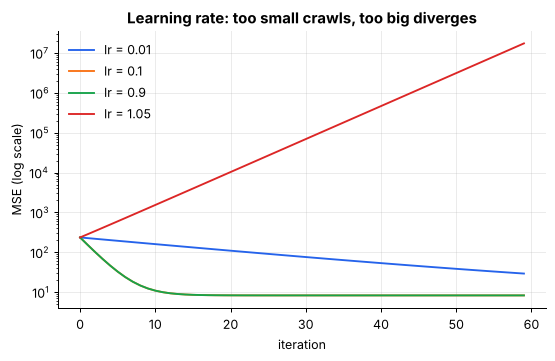

In [7]:
def gradient_descent_slr(x, y, lr=0.1, n_iter=200):
    """Fit y = b0 + b1*x by gradient descent on the MSE. Returns (b0, b1, loss_history)."""
    b0, b1, n = 0.0, 0.0, len(x)
    history = []
    for _ in range(n_iter):
        err = y - (b0 + b1 * x)
        history.append(np.mean(err ** 2))
        b0 -= lr * (-2 / n) * np.sum(err)
        b1 -= lr * (-2 / n) * np.sum(x * err)
    return b0, b1, np.array(history)


# Standardise x first (z-scores) - we'll see why in a moment
x_mean, x_std = x.mean(), x.std()
z = (x - x_mean) / x_std

fig, ax = plt.subplots(figsize=(7, 4))
for lr in [0.01, 0.1, 0.9, 1.05]:
    with np.errstate(over="ignore", invalid="ignore"):
        _, _, hist = gradient_descent_slr(z, y, lr=lr, n_iter=60)
    ax.plot(hist, label=f"lr = {lr}")
ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("MSE (log scale)")
ax.set_title("Learning rate: too small crawls, too big diverges"); ax.legend(); plt.show()

- `lr=0.01`: slow but steady. `lr=0.1`: converges quickly. `lr=0.9`: converges, with oscillation. `lr=1.05`: **explodes**.

Now convert the standardised solution back to the original units and compare with OLS:

In [8]:
b0_z, b1_z, hist = gradient_descent_slr(z, y, lr=0.1, n_iter=300)
# y = b0_z + b1_z * (x - mean)/std  =>  slope = b1_z/std ; intercept = b0_z - b1_z*mean/std
slope_gd = b1_z / x_std
intercept_gd = b0_z - b1_z * x_mean / x_std
print(f"Gradient descent: intercept={intercept_gd:.5f} slope={slope_gd:.5f}")
print(f"Closed form     : intercept={mine.intercept_:.5f} slope={mine.slope_:.5f}")

Gradient descent: intercept=6.76368 slope=0.05119
Closed form     : intercept=6.76368 slope=0.05119


> 🪤 **Common trap.**
>
> **Why standardise?** With raw TV budgets (0–300) the slope's gradient is ~300× bigger than the intercept's, so no single learning rate suits both: a rate big enough for the intercept makes the slope explode. Scaling features to similar ranges makes the valley round and gradient descent happy. This reappears in Logistic Regression, SVMs, KNN and neural networks.

In [9]:
with np.errstate(over="ignore", invalid="ignore"):
    _, b1_raw, hist_raw = gradient_descent_slr(x, y, lr=0.1, n_iter=50)
print("Raw x, lr=0.1  ->  final slope =", b1_raw, "(overflowed!)")
_, b1_raw2, hist_raw2 = gradient_descent_slr(x, y, lr=1e-6, n_iter=2000)
print(f"Raw x, lr=1e-6 ->  slope = {b1_raw2:.4f} after 2000 steps (true: {mine.slope_:.4f}) - still not there")

Raw x, lr=0.1  ->  final slope = -3.567237543554771e+187 (overflowed!)
Raw x, lr=1e-6 ->  slope = 0.0856 after 2000 steps (true: 0.0512) - still not there


---
## ⚙️ 6. The scikit-learn way

In production you'll use `LinearRegression`, which solves least squares with a numerically stable linear-algebra routine (SVD) rather than our explicit formula.

In [10]:
X = ads[["tv_budget_k"]]          # 2-D
Xtr, Xte, ytr, yte = train_test_split(X, ads["sales_k_units"], test_size=0.25, random_state=RANDOM_STATE)

model = LinearRegression().fit(Xtr, ytr)
pred = model.predict(Xte)

print(f"intercept_ = {model.intercept_:.4f}    coef_ = {model.coef_}")
print(f"TEST  RMSE = {np.sqrt(mean_squared_error(yte, pred)):.3f}   R² = {r2_score(yte, pred):.3f}")
print(f"TRAIN R²   = {model.score(Xtr, ytr):.3f}  (similar to test => no overfitting: a line can't memorise!)")

intercept_ = 6.5051    coef_ = [0.05081439]
TEST  RMSE = 3.021   R² = 0.622
TRAIN R²   = 0.695  (similar to test => no overfitting: a line can't memorise!)


---
## 🔍 7. Is the model any good? Residual analysis

A high R² can still hide problems. Plot the residuals. For OLS to be trustworthy (the **LINE** assumptions):

- **L**inearity: the true relationship is roughly a straight line.
- **I**ndependence: rows don't influence each other (no time-series autocorrelation).
- **N**ormality: residuals are roughly bell-shaped (matters mainly for confidence intervals).
- **E**qual variance (homoscedasticity): the scatter doesn't fan out as x grows.

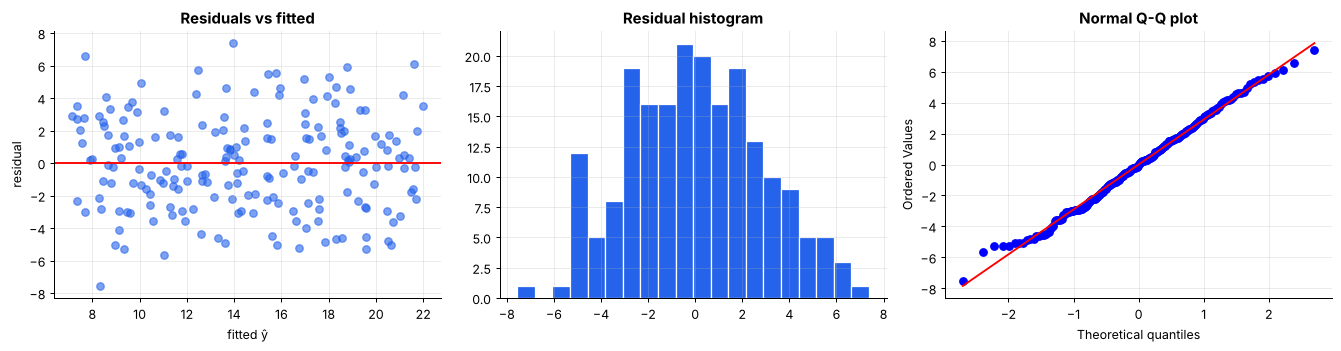

In [11]:
from scipy import stats
fitted = mine.predict(x); resid = y - fitted

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(fitted, resid, alpha=0.6); axes[0].axhline(0, color="r")
axes[0].set_title("Residuals vs fitted"); axes[0].set_xlabel("fitted ŷ"); axes[0].set_ylabel("residual")
axes[1].hist(resid, bins=20, edgecolor="white"); axes[1].set_title("Residual histogram")
stats.probplot(resid, plot=axes[2]); axes[2].set_title("Normal Q-Q plot")
plt.tight_layout(); plt.show()

**How to read them**
- *Residuals vs fitted*: we want a **shapeless cloud** around zero. A **curve** means non-linearity (→ Lesson 03). A **funnel** means unequal variance. Here the cloud has no dramatic curve, but it is wide: TV alone leaves a lot unexplained (R² ≈ 0.69). Radio and newspaper may matter too (→ Lesson 02).
- *Histogram / Q-Q*: points on the diagonal line ⇒ roughly normal residuals.

---
## ☠️ 8. Danger zone

### 8a. Anscombe's quartet: never trust a number you haven't plotted
In 1973 the statistician Francis Anscombe built four small datasets with **identical** means, variances, correlation, regression line and R². Look:

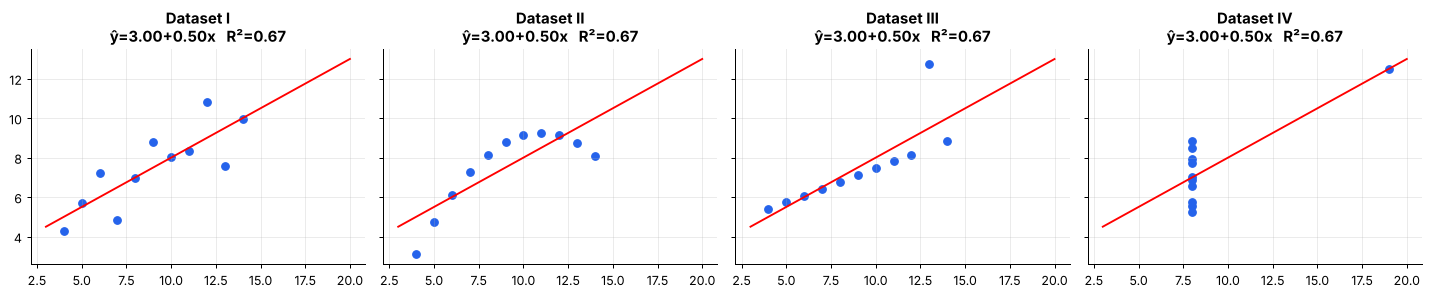

In [12]:
anscombe = {
    "I":   ([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],  [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II":  ([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],  [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III": ([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],  [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV":  ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],      [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for ax, (name, (xa, ya)) in zip(axes, anscombe.items()):
    xa, ya = np.array(xa, float), np.array(ya)
    m = SimpleLinearRegressionScratch().fit(xa, ya)
    ax.scatter(xa, ya); xx = np.linspace(3, 20, 50); ax.plot(xx, m.predict(xx), "r")
    ax.set_title(f"Dataset {name}\nŷ={m.intercept_:.2f}+{m.slope_:.2f}x   R²={m.score(xa, ya):.2f}")
plt.tight_layout(); plt.show()

Four wildly different pictures (a clean line, a curve, a line plus an outlier, and a single point controlling everything) yet the *same* equation and R². **Moral: always plot your data and your residuals.**

### 8b. Outliers have leverage
Least squares squares the errors, so one distant point can drag the entire line.

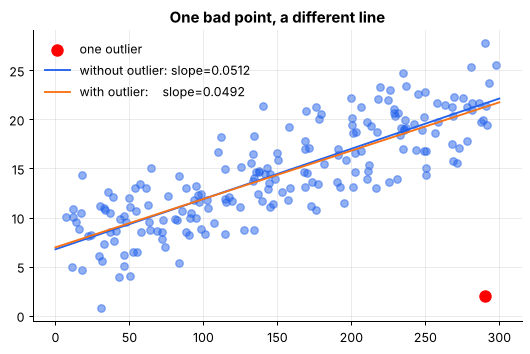

In [13]:
x_out = np.append(x, 290); y_out = np.append(y, 2.0)       # a market with huge TV spend but almost no sales
clean = SimpleLinearRegressionScratch().fit(x, y)
dirty = SimpleLinearRegressionScratch().fit(x_out, y_out)
plt.scatter(x, y, alpha=0.5); plt.scatter([290], [2.0], color="red", s=80, label="one outlier")
xs = np.linspace(0, 300, 50)
plt.plot(xs, clean.predict(xs), label=f"without outlier: slope={clean.slope_:.4f}")
plt.plot(xs, dirty.predict(xs), label=f"with outlier:    slope={dirty.slope_:.4f}")
plt.legend(); plt.title("One bad point, a different line"); plt.show()

### 8c. Extrapolation
The model is only trustworthy **inside the range of x it saw** (TV budgets 5–300). Ask it about 5,000 and it will happily answer, and the answer is fiction.

In [14]:
for tv in [150, 300, 5000]:
    print(f"TV budget {tv:>5}k -> predicted sales {mine.predict([tv])[0]:8.1f}k units  "
          + ("(inside the data range ✅)" if tv <= 300 else "(EXTRAPOLATION ⚠️ - don't trust this)"))

TV budget   150k -> predicted sales     14.4k units  (inside the data range ✅)
TV budget   300k -> predicted sales     22.1k units  (inside the data range ✅)
TV budget  5000k -> predicted sales    262.7k units  (EXTRAPOLATION ⚠️ - don't trust this)


---
## 🎲 9. How sure are we? The bootstrap

Our slope came from *one* sample of 200 markets. Another sample would give a slightly different slope. The **bootstrap** estimates that wobble without any theory: resample the data *with replacement* (same size), refit, repeat hundreds of times, and look at the spread of the slopes.

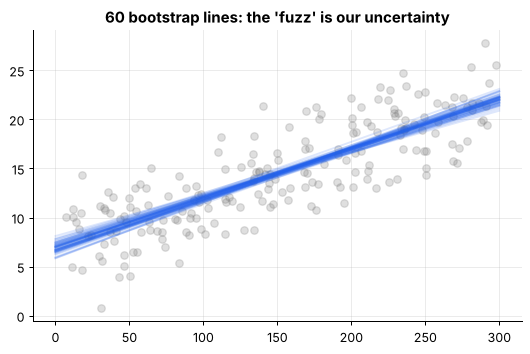

Slope = 0.0512;  95% bootstrap interval = [0.0460, 0.0563]


In [15]:
rng = np.random.default_rng(1)
n = len(x)
boot_slopes = []
plt.scatter(x, y, alpha=0.25, color="gray")
for i in range(300):
    idx = rng.integers(0, n, n)                    # sample n rows WITH replacement
    s, b = np.polyfit(x[idx], y[idx], 1)
    boot_slopes.append(s)
    if i < 60:
        plt.plot(xs, b + s * xs, color="#2563eb", alpha=0.15)
plt.title("60 bootstrap lines: the 'fuzz' is our uncertainty"); plt.show()

lo, hi = np.percentile(boot_slopes, [2.5, 97.5])
print(f"Slope = {mine.slope_:.4f};  95% bootstrap interval = [{lo:.4f}, {hi:.4f}]")

---
## 📋 10. Cheat-sheet: the full profile of Simple Linear Regression

| Question | Answer |
|---|---|
| **Underlying concept** | Best straight line through the data, minimising squared vertical errors. |
| **How it works** | Compute slope = Cov(x,y)/Var(x), intercept = ȳ − slope·x̄ (or walk downhill with gradient descent). |
| **Mathematical foundation** | Ordinary Least Squares; normal equations; gradient of MSE; R² = r². |
| **Important parameters** | `fit_intercept` (default True), `positive` (force slope ≥ 0). Essentially no hyper-parameters: that's a feature! |
| **Advantages** | Instant to train, perfectly interpretable, no tuning, works with tiny data, great baseline. |
| **Disadvantages** | Only straight lines; one feature only; sensitive to outliers; assumptions can be violated. |
| **Complexity** | Training O(n) (a few passes over the data), prediction O(1) per row. Gradient descent: O(n · iterations). |
| **Use cases** | Quick trend estimates, calibration curves, sanity-check baselines, explaining a single relationship to non-technical people. |
| **Limitations** | Cannot capture curvature or interactions; extrapolates blindly; correlation ≠ causation. |

---
## 🧪 11. More worked examples

### Worked Example 1: Interpret and predict

**Question.** Our fitted line is $\hat y = 7.0 + 0.048\,x$ (sales in thousand units, TV in thousand currency). (a) Interpret the slope. (b) Predict sales at $x=150$. (c) Is predicting at $x=1000$ sensible?

**Solution.**
(a) Each extra 1 unit (1 000) of TV spend goes with 0.048 thousand = **48 more units sold**, on average.
(b) $\hat y = 7.0 + 0.048\times150 = 14.2$ → about **14,200 units**.
(c) No. The training data only covered x ≈ 5–300, so 1000 is **extrapolation**: the true relationship will probably saturate (diminishing returns).

### Worked Example 2: From correlation to slope

**Question.** For a dataset, $r=0.8$, $s_x=10$, $s_y=4$. What is the slope? What fraction of variance does the line explain?

**Solution.** $\beta_1=r\,\dfrac{s_y}{s_x}=0.8\times\dfrac{4}{10}=\mathbf{0.32}$ and $R^2=r^2=\mathbf{0.64}$ → 64 % of the variance in y is explained.

In [16]:
r, sx, sy = 0.8, 10, 4
print("slope =", r * sy / sx, "  R² =", r ** 2)

slope = 0.32   R² = 0.6400000000000001


---
### 🧩 Problem 1: Slope and intercept by formula  ⭐

A teacher records hours studied `hrs = [1, 2, 3, 4, 5, 6]` and exam marks `marks = [52, 58, 61, 67, 72, 78]`.

Using **only NumPy and the formulas** from Section 2 (no `polyfit`, no scikit-learn), compute the slope `b1` and intercept `b0`.

In [17]:
# ✅ SOLUTION
hrs = np.array([1, 2, 3, 4, 5, 6]); marks = np.array([52, 58, 61, 67, 72, 78])
xbar, ybar = hrs.mean(), marks.mean()
b1 = np.sum((hrs - xbar) * (marks - ybar)) / np.sum((hrs - xbar) ** 2)
b0 = ybar - b1 * xbar
print(b0, b1)

46.866666666666674 5.085714285714285


**Why this works.** Slope ≈ 5.31 marks per hour and intercept ≈ 46.9 (the predicted mark with zero study hours).

In [18]:
ref = np.polyfit(hrs, marks, 1)
check("slope is correct", lambda: abs(b1 - ref[0]) < 1e-9)
check("intercept is correct", lambda: abs(b0 - ref[1]) < 1e-9)
print("Interpretation: each extra study hour is worth about", round(ref[0], 1), "marks.")

✅  slope is correct
✅  intercept is correct
Interpretation: each extra study hour is worth about 5.1 marks.


---
### 🧩 Problem 2: Predict and score  ⭐⭐

Using your `b0` and `b1` from Problem 1:

1. Write `predict_line(b0, b1, x)` returning predictions.
2. Write `r_squared(y, y_hat)` returning R² = 1 − SSE/SST.
3. Store the R² of your line on the six students in `r2_students`, and the predicted mark for **7 hours** in `pred_7h`.

In [19]:
# ✅ SOLUTION
def predict_line(b0, b1, x):
    return b0 + b1 * np.asarray(x, dtype=float)

def r_squared(y, y_hat):
    y = np.asarray(y, dtype=float)
    return 1 - np.sum((y - y_hat) ** 2) / np.sum((y - y.mean()) ** 2)

r2_students = r_squared(marks, predict_line(b0, b1, hrs))
pred_7h = predict_line(b0, b1, 7)
print(r2_students, pred_7h)

0.9940598201213136 82.46666666666667


**Why this works.** R² is about 0.99 for this nearly-perfectly linear toy data. The 7-hour prediction (~84) is mild extrapolation: fine for a quick estimate, risky for decisions.

In [20]:
ref = np.polyfit(hrs, marks, 1)
check("R² matches sklearn", lambda: abs(r2_students - r2_score(marks, np.polyval(ref, hrs))) < 1e-9)
check("7-hour prediction correct", lambda: abs(pred_7h - np.polyval(ref, 7)) < 1e-9)

✅  R² matches sklearn
✅  7-hour prediction correct


---
### 🧩 Problem 3: One step of gradient descent  ⭐⭐

Write `gd_step(b0, b1, x, y, lr)` that performs **one** gradient-descent update for the MSE loss and returns `(new_b0, new_b1)`.

Then starting from `b0=0, b1=0` on the tiny data `x=[1,2,3]`, `y=[2,4,6]` with `lr=0.1`, store the result of one step in `step1`.

In [21]:
# ✅ SOLUTION
def gd_step(b0, b1, x, y, lr):
    n = len(x)
    err = y - (b0 + b1 * x)
    grad_b0 = -2 / n * np.sum(err)
    grad_b1 = -2 / n * np.sum(x * err)
    return b0 - lr * grad_b0, b1 - lr * grad_b1

step1 = gd_step(0, 0, np.array([1, 2, 3]), np.array([2, 4, 6]), 0.1)
print(step1)

(np.float64(0.8), np.float64(1.8666666666666665))


**Why this works.** b0 moves from 0 to 0 − 0.1·(−8) = 0.8 and b1 from 0 to 0 − 0.1·(−18.667) ≈ 1.867. The line immediately tilts toward the data.

In [22]:
check("new b0 = 0.8", lambda: abs(step1[0] - 0.8) < 1e-9)
check("new b1 ≈ 1.8667", lambda: abs(step1[1] - 1.866667) < 1e-5)

✅  new b0 = 0.8
✅  new b1 ≈ 1.8667


---
### 🧩 Problem 4: Measure the outlier's damage  ⭐⭐

Using the lesson's arrays `x` and `y` (TV vs sales):

1. Add **five** outliers `x=[270, 280, 290, 295, 300]`, `y=[1, 1, 2, 1.5, 0.5]`.
2. Fit lines with `np.polyfit(…, 1)` before and after.
3. Store the two slopes in `slope_before`, `slope_after` and the **percentage drop** in `pct_drop`.

In [23]:
# ✅ SOLUTION
x_bad = np.append(x, [270, 280, 290, 295, 300]); y_bad = np.append(y, [1, 1, 2, 1.5, 0.5])
slope_before = np.polyfit(x, y, 1)[0]
slope_after = np.polyfit(x_bad, y_bad, 1)[0]
pct_drop = (slope_before - slope_after) / slope_before * 100
print(f"{slope_before:.4f} -> {slope_after:.4f}  ({pct_drop:.0f}% drop)")

0.0512 -> 0.0420  (18% drop)


**Why this works.** Only 5 of 205 points (2.4 %) contaminate the data, yet the slope drops substantially: outliers sitting at the *edge* of the x-range have the most leverage.

In [24]:
check("slope got smaller", lambda: slope_after < slope_before)
check("the drop is substantial (>10%)", lambda: pct_drop > 10)

✅  slope got smaller
✅  the drop is substantial (>10%)


---
### 🧩 Problem 5: Bootstrap confidence interval  ⭐⭐⭐

Compute a **95 % bootstrap confidence interval** for the slope of sales on TV budget:

1. Repeat 1000 times: sample `n` row indices with replacement, fit `np.polyfit`, record the slope.
2. `ci_low`, `ci_high` = the 2.5th and 97.5th percentiles. Use `rng = np.random.default_rng(7)`.
3. Set `contains_zero` to `True/False`: can we rule out a zero slope?

In [25]:
# ✅ SOLUTION
rng = np.random.default_rng(7)
n = len(x)
slopes = [np.polyfit(x[i], y[i], 1)[0] for i in (rng.integers(0, n, n) for _ in range(1000))]
ci_low, ci_high = np.percentile(slopes, [2.5, 97.5])
contains_zero = bool(ci_low <= 0 <= ci_high)
print(f"95% CI: [{ci_low:.4f}, {ci_high:.4f}]  contains zero? {contains_zero}")

95% CI: [0.0464, 0.0561]  contains zero? False


**Why this works.** With 200 points and a strong signal the slope is pinned down tightly (width ≈ 0.01) and zero is far outside; TV spending and sales are genuinely related in this data.

In [26]:
full = np.polyfit(x, y, 1)[0]
check("interval is ordered", lambda: ci_low < ci_high)
check("interval contains the full-data slope", lambda: ci_low < full < ci_high)
check("interval is narrow (<0.015)", lambda: ci_high - ci_low < 0.015)
check("zero is excluded", lambda: contains_zero is False)

✅  interval is ordered
✅  interval contains the full-data slope
✅  interval is narrow (<0.015)
✅  zero is excluded


---
## 🧠 Check Your Understanding
Answer each question in your head (or on paper) *before* opening the answer.

**Q1.** Why do we square the residuals instead of just adding them up?

<details><summary>👀 Show answer</summary>

Raw residuals cancel (positives vs negatives), so a terrible line could score zero. Squaring makes every error count, punishes large errors, and gives a smooth function with a unique minimum.

</details>

**Q2.** Where does the OLS line always pass through?

<details><summary>👀 Show answer</summary>

Through the point of means $(\bar x, \bar y)$, because $\beta_0=\bar y-\beta_1\bar x$.

</details>

**Q3.** Your slope is 2.5 when x is measured in metres. What happens to the slope if you measure x in centimetres?

<details><summary>👀 Show answer</summary>

It becomes 0.025: the same effect spread over 100× more units. (R² and predictions stay identical.)

</details>

**Q4.** Two datasets share the same R². Can you conclude the line is equally appropriate? Why/why not?

<details><summary>👀 Show answer</summary>

No, Anscombe's quartet. R² doesn't reveal curvature, outliers or non-constant variance. Plot residuals.

</details>

**Q5.** Gradient descent diverges (loss → ∞). Name the two most likely fixes.

<details><summary>👀 Show answer</summary>

Reduce the learning rate; standardise the features.

</details>

---
## 🔁 Recap

- Simple linear regression fits ŷ = β₀ + β₁x by minimising the sum of squared residuals.
- Closed form: β₁ = Cov(x,y)/Var(x), β₀ = ȳ − β₁x̄. Gradient descent reaches the same answer (scale your features!).
- Interpret the slope in real units; R² = r² tells you the share of variance explained.
- Residual plots reveal violated assumptions; Anscombe's quartet is the reason you plot before you trust.
- Outliers and extrapolation are the two classic ways to get fooled; the bootstrap measures your uncertainty.

### ➡️ Up next: **Multiple Linear Regression**
Open `02_Multiple_Linear_Regression.ipynb` when you're ready.

*You did the hard part: you thought about it, not just ran it. See you in the next one!* 🚀